## Carga y exploración inicial de los datos

Se localiza y carga `ktas.csv` mediante una ruta relativa al proyecto. Se verifican las dimensiones, columnas, tipos de datos y primeras filas del dataset.

In [32]:
from pathlib import Path
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, confusion_matrix, precision_score, f1_score
import joblib, sklearn
from datetime import datetime
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_val_predict

In [ ]:
actual = Path.cwd()

# Si estamos dentro de notebooks, subir un nivel
if actual.name == "notebooks":
    actual = actual.parent

ruta_csv = None

for carpeta in [actual, *actual.parents]:
    candidato = carpeta / "ml" / "data" / "ktas.csv"

    if candidato.is_file():
        ruta_csv = candidato
        break
    
# Comprobar que existe
if ruta_csv is None:
    raise FileNotFoundError(
        f"No se encontró ktas.csv desde la carpeta: {Path.cwd()}\n"
        "Verifica que el archivo esté en ml/data/ktas.csv."
    )
df = pd.read_csv(ruta_csv, sep=";", encoding="latin-1")

print("Archivo encontrado:", ruta_csv.resolve())


Archivo encontrado: C:\Users\Admin\Downloads\ET-Project\TrazaRedHUV\ml\data\ktas.csv


In [11]:
# Revisamos el dataset

print(df.shape)
print(df.columns.tolist())
print(df.dtypes)
df.head(3)

(1267, 25)
['Group', 'Sex', 'Age', 'Patients number per hour', 'Arrival mode', 'Injury', 'Chief_complain', 'Mental', 'Pain', 'NRS_pain', 'SBP', 'DBP', 'HR', 'RR', 'BT', 'Saturation', 'KTAS_RN', 'Diagnosis in ED', 'Disposition', 'KTAS_expert', 'Error_group', 'Length of stay_min', 'KTAS duration_min', 'mistriage', 'urgente']
Group                         int64
Sex                           int64
Age                           int64
Patients number per hour      int64
Arrival mode                  int64
Injury                        int64
Chief_complain               object
Mental                        int64
Pain                          int64
NRS_pain                    float64
SBP                         float64
DBP                         float64
HR                          float64
RR                          float64
BT                          float64
Saturation                  float64
KTAS_RN                       int64
Diagnosis in ED              object
Disposition                

,Group,Sex,Age,Patients number per hour,Arrival mode,Injury,Chief_complain,Mental,Pain,NRS_pain,...,Saturation,KTAS_RN,Diagnosis in ED,Disposition,KTAS_expert,Error_group,Length of stay_min,KTAS duration_min,mistriage,urgente
0,2,2,71,3,3,2,right ocular pain,1,1,2.0,...,100.0,2,Corneal abrasion,1,4,2,86,"5,00",1,0
1,1,1,56,12,3,2,right forearm burn,1,1,2.0,...,NaN,4,"Burn of hand, firts degree dorsum",1,5,4,64,"3,95",1,0
2,2,1,68,8,2,2,"arm pain, Lt",1,1,2.0,...,98.0,4,"Fracture of surgical neck of humerus, closed",2,5,4,862,"1,00",1,0


### Revisión de valores atípicos y distribución de la etiqueta

Se identifican valores inválidos (`??`, `#BOÞ!`) y se examina la distribución de las categorías `KTAS_expert`.

In [ ]:

raros = ["??", "#BOÞ!"]
print("Celdas raras por columna:")
print((df.isin(raros)).sum()[lambda s: s > 0])

# Cómo se reparte la etiqueta KTAS 
print(df["KTAS_expert"].value_counts().sort_index())

Celdas raras por columna:
Chief_complain      5
NRS_pain          556
SBP                25
DBP                29
HR                 20
RR                 22
BT                 18
Saturation          9
dtype: int64
KTAS_expert
1     26
2    220
3    487
4    459
5     75
Name: count, dtype: int64



### Definición de la etiqueta y selección de variables


**Etiqueta objetivo.** Se define como *urgente* a un paciente con clasificación KTAS 1, 2 o 3, y como *no urgente* a uno con KTAS 4 o 5. Según el conteo realizado, hay 733 pacientes urgentes y 534 no urgentes, por lo que las clases están relativamente equilibradas.

**Variables de entrada.** Se utilizan únicamente variables disponibles al momento de la llegada del paciente:

- **Demográficas:** `Sex`, `Age`.
- **Operativas y de llegada:** `Patients number per hour`, `Arrival mode`, `Injury`.
- **Evaluación inicial:** `Mental`, `Pain`, `NRS_pain`, `SBP`, `DBP`, `HR`, `RR`, `BT`, `Saturation`.

La variable `Group`, correspondiente al hospital, se reserva para el análisis de sesgo y no se utiliza como variable de entrada del modelo.

**Variables excluidas.** Se excluyen `KTAS_RN`, `Diagnosis in ED`, `Disposition`, `Error_group`, `Length of stay_min`, `KTAS duration_min` y `mistriage`, porque corresponden a información posterior o relacionada con el proceso de atención. También se excluye `Chief_complain`, por decisión metodológica, ya que el modelo no utilizará el motivo de consulta. Finalmente, `KTAS_expert` se utiliza exclusivamente como etiqueta objetivo para el entrenamiento y la evaluación, nunca como variable de entrada.


### Limpieza de los datos 

In [9]:
raros = ["??", "#BOÞ!"]
df = df.replace(raros, np.nan)

num = ["NRS_pain", "SBP", "DBP", "HR", "RR", "BT", "Saturation"]
for c in num:
    df[c] = pd.to_numeric(df[c], errors="coerce")

df["urgente"] = (df["KTAS_expert"] <= 3).astype(int)
print(df["urgente"].value_counts())
print(df[num].isna().sum())

urgente
1    733
0    534
Name: count, dtype: int64
NRS_pain      556
SBP            25
DBP            29
HR             20
RR             22
BT             18
Saturation    697
dtype: int64


In [10]:
print(pd.crosstab(df["Pain"], df["NRS_pain"].isna()))
print(df["Arrival mode"].value_counts().sort_index())

NRS_pain  False  True 
Pain                  
0             0    553
1           711      3
Arrival mode
1     79
2    266
3    753
4    155
5      2
6     10
7      2
Name: count, dtype: int64


In [12]:
df.loc[df["Pain"] == 0, "NRS_pain"] = 0
df["Arrival mode"] = df["Arrival mode"].replace({6: 5, 7: 5})

print(df["NRS_pain"].isna().sum())          # deberían ser 3
print(df["Arrival mode"].value_counts().sort_index())

3
Arrival mode
1     79
2    266
3    753
4    155
5     14
Name: count, dtype: int64


### Limpieza de KTAS (1267 filas, 24 columnas)
- Los valores `??` y `#BOÞ!` pasaron a vacío y las columnas numéricas se convirtieron a número.
- Etiqueta: `urgente` = KTAS del experto 1, 2 o 3 (733 urgentes, 534 no urgentes).
- `NRS_pain`: los 553 vacíos de pacientes sin dolor (`Pain = 0`) se rellenaron con 0; quedan 3 vacíos.
- `Arrival mode`: los códigos 5, 6 y 7 (2, 10 y 2 pacientes) se juntaron en uno.
- `Saturation` tiene 697 vacíos (55 %): la mediana va a imputar más de la mitad, y hay que decirlo en las limitaciones.
- Los demás vacíos son pocos (18 a 29 por variable) y se imputan con la mediana dentro del pipeline.
- Quedan fuera las variables posteriores a la llegada (`KTAS_RN`, diagnóstico, destino, `Error_group`, estancia, `mistriage`) y `Chief_complain`.

---
## Preparación de los datos

**Separación 80/20.**

El 80 % se utiliza para entrenar y el 20 % se reserva para la evaluación final. `stratify=y` conserva la proporción de clases y `random_state=42` permite reproducir la separación


In [14]:
#Definimos las columnas

cols_num = ["Age", "Patients number per hour", "NRS_pain", "SBP", "DBP", "HR", "RR", "BT", "Saturation"]
cols_cat = ["Sex", "Arrival mode", "Injury", "Mental", "Pain"]

X = df[cols_num + cols_cat]
y = df["urgente"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print(X_train.shape, X_test.shape)
print(y_train.mean().round(3), y_test.mean().round(3))

(1013, 14) (254, 14)
0.578 0.579


**Pipeline de preprocesamiento.**

Agrupa las transformaciones para evitar la fuga de información (data leakage)

- **Numéricas:** imputación con la mediana y escalado con `StandardScaler`.
- **Categóricas:** codificación *One-Hot*.

In [15]:
pre = ColumnTransformer([
    ("num", Pipeline([("mediana", SimpleImputer(strategy="median")),
                      ("escala", StandardScaler())]), cols_num),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cols_cat),
])

modelo = Pipeline([("pre", pre), ("clf", LogisticRegression(max_iter=1000))])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
auc_cv = cross_val_score(modelo, X_train, y_train, cv=cv, scoring="roc_auc")
print(auc_cv.round(3), auc_cv.mean().round(3))

modelo.fit(X_train, y_train)

c:\Users\Admin\Downloads\ET-Project\TrazaRedHUV\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
c:\Users\Admin\Downloads\ET-Project\TrazaRedHUV\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
c:\Users\Admin\Downloads\ET-Project\TrazaRedHUV\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
c:\Users\Admin\Downloads\ET-Project\TrazaRedHUV\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
c:\Users\Admin\Downloads\ET-Project\TrazaRedHUV\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
c:\Users\Admin\Downloads\ET-Project\TrazaRedHUV\.v

[0.816 0.812 0.81  0.787 0.82 ] 0.809


Pipeline(steps=[('pre',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('mediana',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('escala',
                                                                   StandardScaler())]),
                                                  ['Age',
                                                   'Patients number per hour',
                                                   'NRS_pain', 'SBP', 'DBP',
                                                   'HR', 'RR', 'BT',
                                                   'Saturation']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Sex', 'Arrival mode',
                                                   'Injury', 'Mental',
                                                   'Pain'])])),
                ('clf', LogisticRegression(max_iter=1000))])

---
### **Resultados de la validación cruzada**

La proporción de pacientes urgentes se mantiene similar en entrenamiento (0.578) y prueba (0.579), lo que indica una buena separación.

El AUC promedio de **0.809**, con valores entre 0.787 y 0.820, muestra un rendimiento consistente entre las particiones.

---

## Evaluación en el conjunto de prueba

Se evalúa el modelo con el 20 % de los datos reservados, sin utilizarlos durante el entrenamiento.

- **AUC:** mide la capacidad para distinguir entre pacientes urgentes y no urgentes.
- **Umbral:** probabilidad a partir de la cual se clasifica un paciente como urgente.
- **Sensibilidad:** proporción de pacientes urgentes detectados.
- **Especificidad:** proporción de pacientes no urgentes identificados correctamente.
- **Precisión:** proporción de predicciones urgentes que son correctas.
- **F1:** equilibra precisión y sensibilidad.
- **Matriz de confusión:** resume las predicciones correctas e incorrectas, destacando los falsos negativos.

En triage, bajar el umbral a **0.4** puede aumentar la detección de pacientes urgentes, aunque también genere más falsas alarmas.

In [19]:
proba = modelo.predict_proba(X_test)[:, 1]
print("AUC prueba:", round(roc_auc_score(y_test, proba), 3))

def metricas(umbral):
    pred = (proba >= umbral).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    return {"umbral": umbral,
            "sens": round(tp / (tp + fn), 3), "espec": round(tn / (tn + fp), 3),
            "prec": round(precision_score(y_test, pred), 3), "f1": round(f1_score(y_test, pred), 3),
            "TN": tn, "FP": fp, "FN": fn, "TP": tp}

pd.DataFrame([metricas(u) for u in [0.5, 0.4, 0.3]])

AUC prueba: 0.748


,umbral,sens,espec,prec,f1,TN,FP,FN,TP
0,0.5,0.769,0.589,0.720,0.743,63,44,34,113
1,0.4,0.871,0.486,0.699,0.776,52,55,19,128
2,0.3,0.946,0.262,0.638,0.762,28,79,8,139



### Comparación de umbrales

| Umbral | Urgentes perdidos (FN) | Falsas alarmas (FP) | Sensibilidad | Especificidad | F1 |
|---|---:|---:|---:|---:|---:|
| 0.5 | 34 | 44 | 0.769 | 0.589 | 0.743 |
| **0.4** | **19** | **55** | **0.871** | **0.486** | **0.776** |
| 0.3 | 8 | 79 | 0.946 | 0.262 | 0.762 |

- **Umbral 0.4:** reduce los urgentes perdidos de 34 a 19 y alcanza el mejor F1, aunque aumenta las falsas alarmas.
- **Umbral 0.3:** detecta más urgentes, pero genera demasiadas falsas alarmas y reduce la capacidad de priorización.

Se selecciona **0.4** como un equilibrio entre detectar pacientes urgentes y evitar falsas alarmas. Esta decisión debe interpretarse con cautela, dado el tamaño limitado del conjunto de prueba.


### Análisis de sesgo por subgrupo

Se evalúan la sensibilidad, especificidad y los falsos negativos con umbral de 0.4, diferenciando por sexo, edad y hospital.

Una sensibilidad menor indica que el modelo detecta una proporción menor de pacientes urgentes en ese grupo. El análisis por hospital es especialmente importante, ya que los datos proceden únicamente de dos servicios de urgencias.

In [20]:
umbral = 0.4
res = X_test.copy()
res["y"] = y_test
res["pred"] = (proba >= umbral).astype(int)
res["Group"] = df.loc[X_test.index, "Group"]
res["edad_grupo"] = np.where(res["Age"] >= 65, "mayores (65+)", "jóvenes (<65)")

def por_subgrupo(col):
    filas = []
    for g, d in res.groupby(col):
        tn, fp, fn, tp = confusion_matrix(d["y"], d["pred"], labels=[0, 1]).ravel()
        filas.append({col: g, "n": len(d), "urgentes": int(d["y"].sum()),
                      "sens": round(tp / (tp + fn), 3), "espec": round(tn / (tn + fp), 3),
                      "FN": fn})
    return pd.DataFrame(filas)

for col in ["Sex", "edad_grupo", "Group"]:
    print(por_subgrupo(col).to_string(), "\n")

   Sex    n  urgentes   sens  espec  FN
0    1  119        68  0.897  0.490   7
1    2  135        79  0.848  0.482  12 

      edad_grupo    n  urgentes   sens  espec  FN
0  jóvenes (<65)  155        81  0.802  0.595  16
1  mayores (65+)   99        66  0.955  0.242   3 

   Group    n  urgentes   sens  espec  FN
0      1  144        78  0.859  0.561  11
1      2  110        69  0.884  0.366   8 




### **Resultados del análisis de sesgo por subgrupo**

- **Sexo:** la sensibilidad es similar entre grupos (0.897 y 0.848), aunque el grupo 2 presenta cinco urgentes perdidos más.

- **Hospital:** la sensibilidad es parecida (0.859 y 0.884), pero el hospital 2 tiene menor especificidad (0.366), lo que indica más falsas alarmas.

- **Edad:** se observa la mayor diferencia. En jóvenes, la sensibilidad es 0.802 y se pierden 16 urgentes; en mayores, es 0.955 y se pierden 3. Sin embargo, la especificidad en mayores es de apenas 0.242.

**Conclusión:** los resultados sugieren diferencias por edad que deben investigarse. Aunque el modelo detecta mejor a los mayores, también clasifica incorrectamente como urgentes a muchos de ellos. Además, el tamaño de la muestra limita las conclusiones sobre posibles sesgos.

---
## Umbral de caso crítico (R20)

A diferencia del umbral de 0.4, que clasifica a los pacientes como urgentes o no urgentes, el umbral crítico determina cuándo activar una alerta para el médico.

Para justificarlo, se analiza qué proporción de los pacientes que superan distintos umbrales pertenece a las categorías KTAS 1 y 2, correspondientes a los niveles de mayor gravedad.

In [21]:
ktas_test = df.loc[X_test.index, "KTAS_expert"]
graves = (ktas_test <= 2)

filas = []
for u in [0.6, 0.7, 0.8, 0.9]:
    marcados = proba >= u
    filas.append({"umbral": u,
                  "marcados": int(marcados.sum()),
                  "% realmente KTAS 1-2": round(graves[marcados].mean(), 3) if marcados.sum() else None,
                  "% de los KTAS 1-2 que captura": round(marcados[graves].mean(), 3)})
print(f"KTAS 1-2 en prueba: {int(graves.sum())} de {len(graves)}")
print(pd.DataFrame(filas).to_string())

KTAS 1-2 en prueba: 52 de 254
   umbral  marcados  % realmente KTAS 1-2  % de los KTAS 1-2 que captura
0     0.6       133                 0.248                          0.635
1     0.7        96                 0.281                          0.519
2     0.8        62                 0.339                          0.404
3     0.9        26                 0.500                          0.250


In [23]:
for u in [0.8, 0.9]:
    m = proba >= u
    print(u, "| urgentes entre los marcados:", round(y_test[m].mean(), 3),
          "| no urgentes marcados:", int((y_test[m] == 0).sum()))

0.8 | urgentes entre los marcados: 0.839 | no urgentes marcados: 10
0.9 | urgentes entre los marcados: 0.885 | no urgentes marcados: 3



### **Evaluación del umbral de caso crítico**

Notamos que los marcados que no son KTAS 1-2 casi siempre son KTAS 3, que también es urgente así que no son falsas alarmas

Al aumentar el umbral, las alertas son menos frecuentes y concentran pacientes más graves, pero también dejan pasar más casos críticos

Quedamos en 0.9 para el caso crítico y 0.4 para el umbral de decisión. Para la sustentación, los dos se justifican así: 0.4 evita perder urgentes, y 0.9 mantiene la alerta rara para que el médico le haga caso

---
### Guardar el modelo

Se guarda el pipeline entrenado con `joblib`, incluyendo el preprocesamiento y los coeficientes. También se almacenan la versión, las métricas, el umbral y la fecha en un diccionario.

Así, el servicio `ml` puede cargar el modelo al iniciar sin reentrenarlo, y el endpoint `GET /modelo` puede consultar su información.

In [25]:

m = metricas(0.4)  

paquete = {
    "modelo": modelo,
    "version": "1.0",
    "umbral": 0.4,
    "umbral_critico": 0.9,
    "columnas_num": cols_num,
    "columnas_cat": cols_cat,
    "metricas": {
        "auc_prueba": round(float(roc_auc_score(y_test, proba)), 3),
        "auc_cv": round(float(auc_cv.mean()), 3),
        "sensibilidad": float(m["sens"]), "especificidad": float(m["espec"]),
        "precision": float(m["prec"]), "f1": float(m["f1"]),
        "matriz_confusion": {"TN": int(m["TN"]), "FP": int(m["FP"]),
                             "FN": int(m["FN"]), "TP": int(m["TP"])},
    },
    "fecha": datetime.now().isoformat(timespec="seconds"),
    "sklearn": sklearn.__version__,
}

RUTA_ML = Path(r"C:\Users\Admin\Downloads\ET-Project\TrazaRedHUV\ml")
(RUTA_ML / "modelo").mkdir(exist_ok=True)

joblib.dump(paquete, RUTA_ML / "modelo" / "ktas_modelo.joblib")
print(paquete["sklearn"], paquete["metricas"])

1.5.2 {'auc_prueba': 0.748, 'auc_cv': 0.809, 'sensibilidad': 0.871, 'especificidad': 0.486, 'precision': 0.699, 'f1': 0.776, 'matriz_confusion': {'TN': 52, 'FP': 55, 'FN': 19, 'TP': 128}}


**Métricas del modelo.**

El modelo obtiene un AUC de **0.748** en prueba y de **0.809** en validación cruzada. Con un umbral de 0.4, alcanza una sensibilidad de **0.871**, detectando el 87.1 % de los pacientes urgentes.

---

### Prueba del servicio de predicción

**1. Consultar la información del modelo**

Verifica que el modelo esté cargado y que sus métricas y umbrales estén disponibles.

```powershell
docker compose exec ml python -c "import urllib.request as u; print(u.urlopen('http://localhost:8001/modelo').read().decode())"
```

**2. Enviar un paciente de prueba**

Envía datos de ejemplo al endpoint de predicción.

```powershell
docker compose exec ml python -c "import json,urllib.request as u; d={'id_seudonimo':'p-001','sexo':2,'edad':75,'pacientes_por_hora':5,'modo_llegada':3,'lesion':1,'mental':1,'dolor':1,'nrs_dolor':8,'sbp':85,'dbp':50,'fc':125,'fr':26,'temperatura':38.5,'saturacion':86}; r=u.Request('http://localhost:8001/predecir',json.dumps(d).encode(),{'Content-Type':'application/json'}); print(u.urlopen(r).read().decode())"
```

**3. Resultado esperado**

- Probabilidad: `0.9954`.
- Clasificación: urgente (`true`).
- Caso crítico: `true`.
- Nivel: `critico`.
- Versión del modelo: `1.0`.

**4. Comprobar casos de diferente gravedad.**

El primer paciente de prueba tiene 75 años, saturación de oxígeno del 86 %, presión arterial baja y frecuencia cardíaca elevada. El modelo devuelve una probabilidad de **0.9954** y lo clasifica como `critico`, activando la alerta.

También se puede probar el otro extremo con un paciente joven y signos vitales normales para comprobar si el modelo lo clasifica como `no urgente`. Así se verifica que el servicio responde ante perfiles clínicos diferentes.

---
### `POST /entrenar`

Se traslada el código de entrenamiento del cuaderno a un archivo `entrenar.py`, integrando la limpieza, la separación de datos, el pipeline y el guardado del modelo para que el servicio pueda reentrenarlo cuando se solicite.

Hay dos aspectos importantes:

- **Reutilización:** mantener las mismas reglas de preprocesamiento y entrenamiento del cuaderno.
- **Integración:** permitir que el endpoint `POST /entrenar` ejecute el proceso y guarde el nuevo modelo para su uso posterior.

## Preparamos y buscar el número de grupos (codo + silueta)

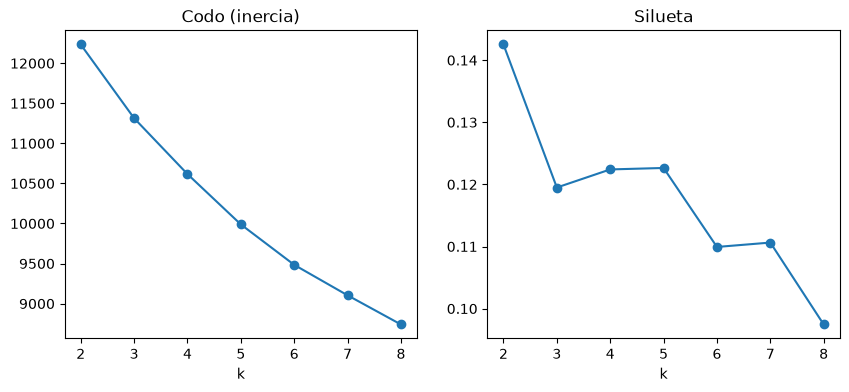

{2: np.float64(0.143), 3: np.float64(0.119), 4: np.float64(0.122), 5: np.float64(0.123), 6: np.float64(0.11), 7: np.float64(0.111), 8: np.float64(0.097)}


In [29]:

# Preprocesamiento del modelo (mediana , escala , one-hot) sobre todos los pacientes reales
Z = pre.fit_transform(X)
if hasattr(Z, "toarray"):
    Z = Z.toarray()

ks = range(2, 9)
inercia, silueta = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Z)
    inercia.append(km.inertia_)
    silueta.append(silhouette_score(Z, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(ks, inercia, marker="o"); ax[0].set_title("Codo (inercia)"); ax[0].set_xlabel("k")
ax[1].plot(ks, silueta, marker="o"); ax[1].set_title("Silueta"); ax[1].set_xlabel("k")
plt.show()
print(dict(zip(ks, np.round(silueta, 3))))

la silueta es baja en todos los k (0.10–0.14), lo que indica estructura débil; se eligió k=4 como el menor valor donde la silueta se recupera, coincidiendo con el codo suave, y porque permite una interpretación clínica más rica que k=2

## Describir cada grupo

In [30]:
k = 4  
km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Z)
res_c = X.copy()
res_c["cluster"] = km.labels_
res_c["urgente"] = y
res_c["KTAS"] = df.loc[X.index, "KTAS_expert"]

print(res_c.groupby("cluster").agg(
    n=("urgente", "size"), edad=("Age", "mean"), sbp=("SBP", "median"),
    fc=("HR", "median"), sat=("Saturation", "median"),
    nrs=("NRS_pain", "mean"), pct_urgente=("urgente", "mean")
).round(2))

           n   edad    sbp     fc   sat   nrs  pct_urgente
cluster                                                   
0        309  56.68  160.0   86.0  98.0  2.29         0.58
1        535  49.18  120.0   80.0  98.0  4.13         0.47
2        417  59.20  120.0   83.0  98.0  0.01         0.71
3          6  73.67  130.0  102.0  75.0  1.00         1.00


## ¿En qué grupo se confunde el modelo?

In [ ]:


proba_all = cross_val_predict(modelo, X, y, cv=cv, method="predict_proba")[:, 1]
res_c["pred"] = (proba_all >= 0.4).astype(int)

def resumen(d):
    tn, fp, fn, tp = confusion_matrix(d["urgente"], d["pred"], labels=[0, 1]).ravel()
    return pd.Series({"n": len(d), "sens": tp / (tp + fn) if tp + fn else np.nan,
                      "espec": tn / (tn + fp) if tn + fp else np.nan,
                      "FN": fn, "FP": fp, "error": (fn + fp) / len(d)})

print(res_c.groupby("cluster").apply(resumen).round(3))

c:\Users\Admin\Downloads\ET-Project\TrazaRedHUV\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
c:\Users\Admin\Downloads\ET-Project\TrazaRedHUV\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
c:\Users\Admin\Downloads\ET-Project\TrazaRedHUV\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
c:\Users\Admin\Downloads\ET-Project\TrazaRedHUV\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
c:\Users\Admin\Downloads\ET-Project\TrazaRedHUV\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


             n   sens  espec    FN     FP  error
cluster                                         
0        309.0  0.866  0.485  24.0   67.0  0.294
1        535.0  0.810  0.710  48.0   82.0  0.243
2        417.0  0.973  0.165   8.0  101.0  0.261
3          6.0  1.000    NaN   0.0    0.0  0.000


C:\Users\Admin\AppData\Local\Temp\ipykernel_35884\4239375513.py:12: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  print(res_c.groupby("cluster").apply(resumen).round(3))


## sintéticos

In [ ]:
rng = np.random.default_rng(42)
n_sint = {0: 60, 1: 60, 2: 60, 3: 10}   
cols_ruido = ["Age", "Patients number per hour", "NRS_pain", "SBP", "DBP", "HR", "RR", "BT", "Saturation"]

filas = []
for c, n in n_sint.items():
    base = res_c.loc[res_c["cluster"] == c, cols_num + cols_cat]
    sd, lo, hi = base[cols_ruido].std(), base[cols_ruido].min(), base[cols_ruido].max()
    m = base.sample(n, replace=True, random_state=42).reset_index(drop=True)
    for col in cols_ruido:
        m[col] = (m[col] + rng.normal(0, 0.2 * sd[col], n)).clip(lo[col], hi[col])
    m.loc[m["Pain"] == 0, "NRS_pain"] = 0
    for col in ["Age", "Patients number per hour", "NRS_pain", "SBP", "DBP", "HR", "RR", "Saturation"]:
        m[col] = m[col].round()
    m["BT"] = m["BT"].round(1)
    m["cluster"], m["origen"] = c, "sintetico"
    filas.append(m)

sinteticos = pd.concat(filas, ignore_index=True)
     
# Conteo por cluster (lo que devolverá el endpoint)
reales = res_c[["cluster"]].assign(origen="real")
print(pd.concat([reales, sinteticos[["cluster", "origen"]]]).groupby(["cluster", "origen"]).size().unstack())

sinteticos.to_csv(ruta_csv.parent / "pacientes_sinteticos.csv", index=False)

origen   real  sintetico
cluster                 
0         309         60
1         535         60
2         417         60
3           6         10
